# Slice Selection

**Part:** E – RF pulses and excitation · **Reading time:** ~50 min · **Pass 1 overview:** [From signal to image](../pass1_big_picture/P1.3_From_Signal_to_Image.ipynb) · **Refreshers you may want:** [complex numbers & rotations](../refreshers/RM2_Complex_Numbers_and_Rotations.ipynb), [continuous FT](../refreshers/RM3_Continuous_FT_and_DFT.ipynb), [Fourier properties (shift theorem)](../refreshers/RM4_Fourier_Properties.ipynb), [Fourier pairs](../refreshers/RM5_Fourier_Pairs_and_Sampling.ipynb)

An important tool in MRI for localization is **slice selection**. It is done by applying a magnetic field gradient during an RF pulse that has been designed to excite only a limited band of frequencies; because the gradient makes the frequency depend on position, only a limited region of space – a slice – is excited.

**Why this chapter matters.** Almost every 2D MRI scan starts with a slice-selective excitation. The slice thickness, its position, its sharpness, the signal loss if the phase across the slice is not refocused, and the chemical-shift displacement of fat are all set by two numbers: the RF bandwidth and the gradient amplitude. Their limits (gradient strength, RF peak power, SAR) are a real engineering trade-off.

## Learning goals

1. Describe how images are formed
    * Describe slice selection using RF pulses
2. *(added)* Derive slice thickness $\Delta z=BW_{rf}/(\bar\gamma G_{z,SS})$ and slice offset $f_{off}=\bar\gamma G_{z,SS}z_{off}$, and compute realistic numbers.
3. *(added)* Explain why a refocusing ("rewinder") gradient lobe of about −½ the slice-select area is needed, and simulate the signal loss without it.
4. *(added)* Simulate slice profiles with gradients using the Bloch equation.
5. *(added)* Explain trade-offs: thin slices vs gradient strength and pulse duration; chemical-shift displacement of the fat slice.

## Symbols used in this chapter

| Symbol | Meaning (plain words) | SI unit | Typical value / remark |
|---|---|---|---|
| $\vec r=[x,y,z]^T$, $z$ | position; $z$ = slice-select direction here | m | |
| $\vec G(t)$, $G_{z,SS}$ | gradient vector; slice-select gradient amplitude | T/m | 5–40 mT/m |
| $G_{max}$, $SR$ | maximum gradient amplitude, slew rate | T/m, T/m/s | 40–80 mT/m, 100–200 T/m/s |
| $t_{ramp}$ | gradient ramp (rise) time, $\approx G/SR$ | s | 0.05–0.3 ms |
| $\gamma$, $\bar\gamma=\gamma/2\pi$ | gyromagnetic ratio (angular / ordinary) | rad s⁻¹ T⁻¹, Hz/T | 42.58 MHz/T (¹H) |
| $f(\vec r)$ | precession frequency offset at position $\vec r$ (rotating frame) | Hz | |
| $\Delta f$ | off-resonance of a spin (from any cause) | Hz | |
| $b_1(t)$ | complex RF envelope in the rotating frame | T | µT |
| $T_{rf}$ | RF pulse duration | s | 1–5 ms |
| $BW_{rf}$, $TBW$ | RF bandwidth; time–bandwidth product $T_{rf}BW_{rf}$ | Hz, – | 1–4 kHz; 2–12 |
| $\Delta z$ | slice thickness (FWHM of the profile) | m | 1–10 mm |
| $z_{off}$, $f_{off}$ | slice position offset; matching RF frequency offset | m, Hz | |
| $\theta$ | flip angle | rad / ° | |
| $M_{xy}$, $M_z$, $M_0$ | transverse (complex), longitudinal, equilibrium magnetization | normalized | $M_0=1$ |
| $\phi(z)$ | phase of $M_{xy}$ across the slice | rad | |
| $A_{SS}$, $A_{rw}$ | gradient area (time integral) of the slice-select lobe; of the rewinder lobe | T s/m | $A_{rw}\approx-\tfrac12A_{SS}$ |
| $k_z$ | k-space coordinate $\bar\gamma\int G_z\,dt$ (phase per metre / $2\pi$) | 1/m | |
| $\Delta f_{cs}$ | chemical shift of fat relative to water | Hz | −224 Hz @1.5 T, −447 Hz @3 T |
| $\Delta z_{cs}$ | chemical-shift displacement of the fat slice | m | |
| $s$ | net signal of the slice, $\propto\int M_{xy}(z)dz$ | a.u. | |

> **⚠️ Common confusion:** $\Delta z$ here is the slice *thickness*; it is unrelated to the image pixel size $\delta$. And $\Delta f$ (any frequency offset of a spin) is not the same as $BW_{rf}$ (the width of the band the pulse excites).

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))   # make ../mri_tools.py importable
import numpy as np
import matplotlib.pyplot as plt
import mri_tools as mt
mt.setup_plots()
%matplotlib inline

## Spatial selectivity

As described in the [previous chapter](E1_RF_Pulses.ipynb), RF pulses can be designed to excite a limited range of frequencies, characterized by their frequency profile. Magnetic field gradients create variations in the magnetic field across space: with a gradient on, the z-field is $B_z(\vec r)=B_0+\vec G\cdot\vec r$, so the precession frequency becomes position dependent. In the rotating frame (at $f_0=\bar\gamma B_0$) the frequency offset is

$$f(\vec r,t) = \bar \gamma\, \vec G(t) \cdot \vec r .$$

*In words:* with a gradient, the frequency at which spins precess (relative to the scanner frequency) is proportional to their position along the gradient direction – the gradient is a "ruler made of frequencies".

where $f$ [Hz] is the frequency offset, $\bar\gamma=42.58$ MHz/T, $\vec G$ [T/m] the gradient vector and $\vec r$ [m] the position. For a z-gradient only, $f(z)=\bar\gamma G_zz$. **Numbers:** $G_z$ = 10 mT/m gives $42.58\times10^6\cdot0.01=425.8$ kHz per metre = **426 Hz per mm**.

So when a gradient is turned on during an RF pulse, the frequency profile of the pulse is converted into a spatial profile. This is illustrated in the following diagram:

![Illustration of how gradients convert an RF pulse frequency profile into a spatial profile](../images/Slice_Selection-intuition.png)

*Figure: left, the RF pulse excites a band of frequencies; middle, the gradient maps position to frequency (a straight line $f=\bar\gamma G_zz$); right, the excited frequencies correspond to an excited slab of positions.*

> **🧭 Intuition:** Think of the gradient as tuning every z-position to a different "radio station". The RF pulse broadcasts on a band of stations; only the positions tuned into that band respond.

## Slice-selective RF pulses

The goal of slice selection is to excite a limited region in space, commonly referred to as a **slice** or **slab**. (The term "slab selection" typically refers to exciting a thicker slice in 3D imaging, see [H1 Volumetric Imaging](H1_Volumetric_Imaging.ipynb).)

### Pulse design

**RF pulse shape** – since the goal is to excite only a limited range of frequencies, a sinc-like pulse shape is used to create a rect-like frequency profile (see [RF Pulses](E1_RF_Pulses.ipynb) and [RF Pulse Design](E3_RF_Pulse_Design.ipynb)).

**Magnetic field gradient** – a constant gradient is applied during the pulse. The gradient direction corresponds to the direction of the slice selection (the slice normal), and the gradient amplitude, together with the RF bandwidth, determines the thickness of the slice. This is known as the **slice-select gradient**.

![Slice selective RF pulse with parameters labeled](../images/Slice_Selection-Sample_Pulses.png)

*Figure: a slice-selective excitation in a pulse-sequence diagram: the RF pulse (top) is played during a constant slice-select gradient $G_{z,SS}$, which is followed by a negative refocusing lobe.*

Conventionally, pulse sequence diagrams put the slice selection along the Z gradient direction, with the imaging gradients on X and Y. In practice any combination of X, Y and Z gradients can be used: playing $\vec G=G_{SS}\,\hat n$ selects a slice perpendicular to the unit vector $\hat n$, so **oblique** slices cost nothing extra (the scanner simply distributes $G_{SS}$ over the three physical gradient coils).

### Slice thickness

Spins at position $z$ precess at $f(z)=\bar\gamma G_{z,SS}z$. The pulse excites the frequencies $|f|<BW_{rf}/2$, hence the positions $|z|<BW_{rf}/(2\bar\gamma G_{z,SS})$. The width of this region is the slice thickness:

$$ \Delta z = \frac{BW_{rf}}{\bar{\gamma}\, G_{z,SS}} .$$

*In words:* the slice is thinner when the pulse excites a narrower band of frequencies, or when the gradient is steeper (more Hz per mm).

where $\Delta z$ [m] is the slice thickness, $BW_{rf}$ [Hz] the RF bandwidth, $\bar\gamma$ [Hz/T], $G_{z,SS}$ [T/m] the slice-select gradient. Since $BW_{rf}=TBW/T_{rf}$, equivalently $\Delta z=TBW/(\bar\gamma G_{z,SS}T_{rf})$.

### Slice shifting

The slice location can be shifted by a distance $z_{off}$ by shifting the frequency of the RF pulse by $f_{off}$, i.e. the frequency at which spins at $z_{off}$ precess:

$$ f_{off} = \bar{\gamma}\, G_{z,SS}\, z_{off} .$$

*In words:* to move the slice, retune the RF transmitter to the frequency that the gradient assigns to the new slice centre.

where $f_{off}$ [Hz] is the RF frequency offset and $z_{off}$ [m] the slice position. In the rotating-frame envelope this is the **shift theorem**: $b_1(t)\to b_1(t)e^{-i2\pi f_{off}t}$ (with our clockwise-precession convention, see [E1](E1_RF_Pulses.ipynb)). Multi-slice imaging simply plays the same pulse with different $f_{off}$ in successive excitations.

In [2]:
# Slice thickness and offset frequency for realistic numbers
gb = mt.GAMMA_BAR
print("Hz per mm for G = 10 mT/m:", gb * 10e-3 * 1e-3)
print("\nslice thickness dz [mm] for BW_rf (rows) and G_ss (columns):")
Gs = np.array([5, 10, 20, 40]) * 1e-3               # [T/m]
print("BW_rf [kHz] | " + " | ".join(f"G={g*1e3:4.0f} mT/m" for g in Gs))
for BW in [1e3, 2e3, 4e3]:
    print(f"{BW/1e3:11.0f} | " + " | ".join(f"{BW/(gb*g)*1e3:13.2f}" for g in Gs))
G_ss, z_off = 10e-3, 30e-3
print(f"\nf_off for z_off = {z_off*1e3:.0f} mm at G = {G_ss*1e3:.0f} mT/m: {gb*G_ss*z_off/1e3:.2f} kHz")

Hz per mm for G = 10 mT/m: 425.77

slice thickness dz [mm] for BW_rf (rows) and G_ss (columns):
BW_rf [kHz] | G=   5 mT/m | G=  10 mT/m | G=  20 mT/m | G=  40 mT/m
          1 |          4.70 |          2.35 |          1.17 |          0.59
          2 |          9.39 |          4.70 |          2.35 |          1.17
          4 |         18.79 |          9.39 |          4.70 |          2.35

f_off for z_off = 30 mm at G = 10 mT/m: 12.77 kHz


*Interpretation:* typical clinical slices (3–5 mm) come from a 1–4 kHz pulse with 5–20 mT/m – well below the 40–80 mT/m that modern gradients can deliver, because other constraints (pulse duration, peak $B_1$, chemical shift) matter too. Moving the slice 3 cm away from the isocentre requires a frequency offset of only ~13 kHz on top of 127.7 MHz.

## Slice profile simulation (Bloch equation with gradients)

Now we simulate the actual slice profile: a 90° Hamming-windowed sinc pulse (TBW 4, $T_{rf}$ = 2 ms → $BW_{rf}$ = 2 kHz) played with a constant gradient chosen for $\Delta z$ = 5 mm, followed by a rewinder. We place 301 spins along $z$ from −15 to +15 mm and use `mt.bloch_simulate(B1=..., G=..., r=...)`, which adds the field $\vec G(t)\cdot\vec r_j$ for every spin $j$ at every time step.

BW_rf = 2000 Hz, G_ss = 9.39 mT/m


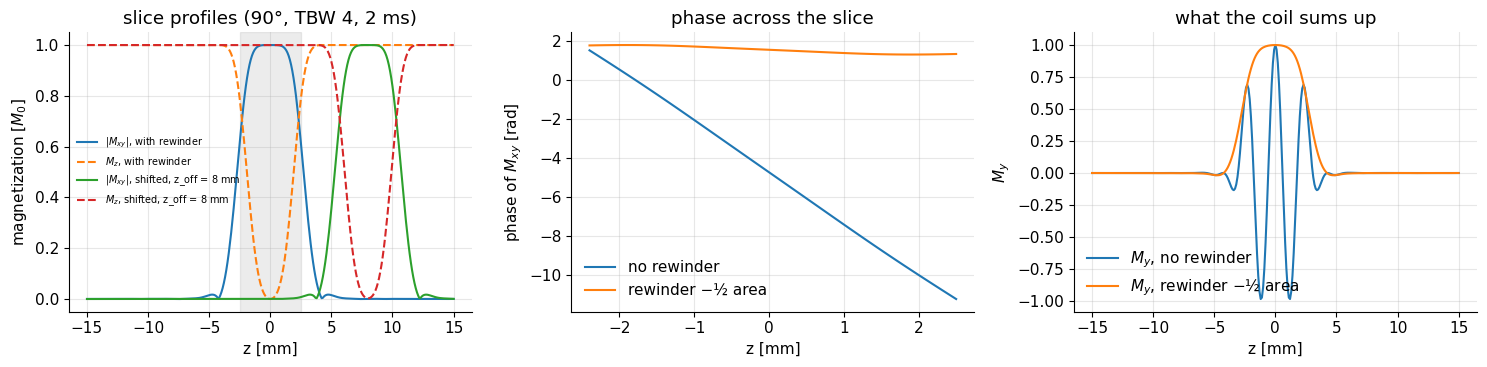

simulated FWHM slice thickness: 5.40 mm (target 5.0 mm)
centre of shifted slice: 7.99 mm


In [3]:
def sinc_pulse(TBW, T_rf, dt, theta=np.pi/2):
    """Hamming-windowed sinc b1(t) [T] with time-bandwidth TBW, duration T_rf [s], step dt [s], flip theta [rad]."""
    n = int(round(T_rf / dt)); t = (np.arange(n) + 0.5) * dt; x = (t - T_rf / 2) / T_rf
    shape = np.sinc(TBW * x) * (0.54 + 0.46 * np.cos(2 * np.pi * x))
    return t, (theta * shape / (mt.GAMMA * shape.sum() * dt)).astype(complex)

def slice_select(b1, G_ss, dt, z, rewind_frac=0.5, n_rw=100, df=0.0, f_off=0.0):
    """Simulate slice-selective excitation: b1 played during constant G_ss [T/m], then a rewinder
    lobe (n_rw steps) with area -rewind_frac * G_ss * T_rf. Spins at positions z [m] with off-resonance df [Hz].
    The RF is frequency-shifted by f_off [Hz] (slice offset). Returns M (Ns, 3) at the end."""
    n = len(b1); T_rf = n * dt
    t = (np.arange(n) + 0.5) * dt
    rf = np.concatenate([b1 * np.exp(-2j * np.pi * f_off * (t - T_rf / 2)), np.zeros(n_rw)])
    G = np.zeros((n + n_rw, 3))
    G[:n, 2] = G_ss
    G[n:, 2] = -rewind_frac * G_ss * T_rf / (n_rw * dt)        # area -rewind_frac * G_ss * T_rf
    r = np.zeros((len(z), 3)); r[:, 2] = z
    _, M = mt.bloch_simulate(B1=rf, dt=dt, G=G, r=r, df=df, return_all=False)
    return M

dt, T_rf, TBW, dz = 10e-6, 2e-3, 4, 5e-3
BW = TBW / T_rf
G_ss = BW / (mt.GAMMA_BAR * dz)                                # gradient for a 5 mm slice
print(f"BW_rf = {BW:.0f} Hz, G_ss = {G_ss*1e3:.2f} mT/m")
z = np.linspace(-15e-3, 15e-3, 301)
t, b1 = sinc_pulse(TBW, T_rf, dt)
M_rw = slice_select(b1, G_ss, dt, z, rewind_frac=0.5)
M_no = slice_select(b1, G_ss, dt, z, rewind_frac=0.0)
z_off = 8e-3
M_sh = slice_select(b1, G_ss, dt, z, rewind_frac=0.5, f_off=mt.GAMMA_BAR * G_ss * z_off)

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for M, lab in [(M_rw, "with rewinder"), (M_sh, f"shifted, z_off = {z_off*1e3:.0f} mm")]:
    ax[0].plot(z * 1e3, np.abs(M[:, 0] + 1j * M[:, 1]), label=r"$|M_{xy}|$, " + lab)
    ax[0].plot(z * 1e3, M[:, 2], "--", label=r"$M_z$, " + lab)
ax[0].axvspan(-dz / 2 * 1e3, dz / 2 * 1e3, color="gray", alpha=0.15)
ax[0].set(xlabel="z [mm]", ylabel="magnetization [$M_0$]", title="slice profiles (90°, TBW 4, 2 ms)"); ax[0].legend(fontsize=7)
inside = np.abs(z) < dz / 2
for M, lab in [(M_no, "no rewinder"), (M_rw, "rewinder −½ area")]:
    ax[1].plot(z[inside] * 1e3, np.unwrap(np.angle(M[inside, 0] + 1j * M[inside, 1])), label=lab)
    ax[2].plot(z * 1e3, M[:, 1], label=r"$M_y$, " + lab)
ax[1].set(xlabel="z [mm]", ylabel=r"phase of $M_{xy}$ [rad]", title="phase across the slice"); ax[1].legend()
ax[2].set(xlabel="z [mm]", ylabel=r"$M_y$", title="what the coil sums up"); ax[2].legend()
plt.tight_layout(); plt.show()
p = np.abs(M_rw[:, 0] + 1j * M_rw[:, 1]); above = z[p >= 0.5 * p.max()]
print(f"simulated FWHM slice thickness: {(above[-1]-above[0])*1e3:.2f} mm (target {dz*1e3:.1f} mm)")
p = np.abs(M_sh[:, 0] + 1j * M_sh[:, 1]); print(f"centre of shifted slice: {np.sum(p*z)/np.sum(p)*1e3:.2f} mm")

*Interpretation:* the excited region is ≈ 5 mm wide as designed (the $|M_{xy}|$ FWHM comes out at 5.4 mm because $\sin\theta$ is flat near 90°, which pushes the half-maximum points outward; $M_z=\cos\theta$ instead looks V-shaped), with $M_z\approx0$ in the centre and $\approx1$ outside. The frequency-shifted pulse moves the slice to +8 mm without changing its shape. Without the rewinder the phase of $M_{xy}$ winds by many radians across the slice (middle), so $M_y$ oscillates in sign (right) and the coil, which sums over the whole slice, sees almost nothing. With the rewinder the phase is flat and all spins add up.

### Refocusing (rewinder) gradient

At the end of the RF pulse in a slice-selective excitation there is unrefocused phase across the slice: the transverse magnetization points in different directions at different $z$. If imaging occurs at this point, these contributions cancel, leading to signal loss. Therefore a refocusing gradient must be applied before imaging. This gradient has an area of (about) **minus half** of the slice-select gradient area during the RF pulse.

**Why one half?** Use the small-tip result from [E1](E1_RF_Pulses.ipynb): with a gradient, the off-resonance of a spin at $z$ is $\Delta f=\bar\gamma G_{z,SS}z$, and

$$M_{xy}(z,T_{rf})\approx i\gamma M_0\,e^{-i\pi\bar\gamma G_{z,SS}z\,T_{rf}}\int b_1^{c}(s)\,e^{+i2\pi\bar\gamma G_{z,SS}z\,s}\,ds .$$

*In words:* for a symmetric pulse, the spins behave as if they had been tipped instantaneously at the **centre** of the pulse and had then precessed under the gradient for the remaining half pulse, $T_{rf}/2$; that leaves a phase that is linear in $z$.

where $b_1^c(s)$ is the pulse centred at $s=0$ (real and even for a sinc, so the integral is real), $G_{z,SS}$ [T/m], $T_{rf}$ [s]. The phase across the slice is

$$\phi(z)=-2\pi\bar\gamma\,G_{z,SS}\,\frac{T_{rf}}{2}\,z=-\gamma\,z\,\frac{A_{SS}}{2},\qquad A_{SS}=G_{z,SS}T_{rf}.$$

*In words:* the phase at position $z$ equals $-\gamma z$ times *half* the slice-select gradient area.

where $A_{SS}$ [T s/m] is the area of the slice-select lobe. A subsequent gradient lobe with area $A_{rw}$ adds phase $-\gamma zA_{rw}$. Choosing $A_{rw}=-A_{SS}/2$ cancels $\phi(z)$ for all $z$ at once. In k-space language ([F2 K-space](F2_K-space.ipynb), [J1 Excitation k-space](J1_Excitation_K-space.ipynb)): the excited pattern sits at $k_z=\bar\gamma A_{SS}/2$ after the pulse; the rewinder moves it back to $k_z=0$, where the coil "sees" the full sum.

**How much signal is lost without a rewinder?** The coil measures $s\propto\int M_{xy}(z)\,dz$. With a linear phase of total range $\gamma G T_{rf}\Delta z/2 = \pi\,TBW$ across the slice (use $\Delta z=TBW/(\bar\gamma GT_{rf})$), the phasors wind $TBW/2$ full turns and nearly cancel. Let's sweep the rewinder area.

30°: signal without rewinder = 0.2 % of optimum; optimum rewinder fraction = 0.500


90°: signal without rewinder = 2.7 % of optimum; optimum rewinder fraction = 0.525


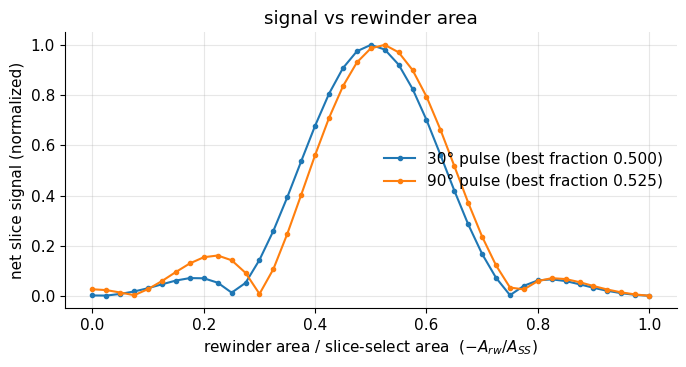

In [4]:
fracs = np.linspace(0, 1, 41)
fig, ax = plt.subplots(figsize=(7, 3.8))
for th in [30, 90]:
    _, b1 = sinc_pulse(TBW, T_rf, dt, np.deg2rad(th))
    sig = np.array([np.abs(np.sum((lambda M: M[:, 0] + 1j * M[:, 1])(slice_select(b1, G_ss, dt, z, rewind_frac=fr))))
                    for fr in fracs])
    sig /= sig.max()
    best = fracs[np.argmax(sig)]
    ax.plot(fracs, sig, "o-", ms=3, label=f"{th}° pulse (best fraction {best:.3f})")
    print(f"{th}°: signal without rewinder = {sig[0]*100:.1f} % of optimum; optimum rewinder fraction = {best:.3f}")
ax.set(xlabel=r"rewinder area / slice-select area  ($-A_{rw}/A_{SS}$)", ylabel="net slice signal (normalized)",
       title="signal vs rewinder area")
ax.legend(); plt.tight_layout(); plt.show()

*Interpretation:* without a rewinder only a few % of the signal survives; the optimum is at ≈ 0.5 of the slice-select area, as predicted. For the 90° pulse the optimum is slightly above 0.5 (≈ 0.52): the small-tip picture of "instantaneous tip at the pulse centre" is only approximately true at large flip angles. Scanners and pulse-design tools therefore compute the exact rewinder area for each pulse (for asymmetric pulses, e.g. minimum-phase SLR pulses, the fraction is very different from ½).

> **🔧 Engineering reality:** Real gradients are trapezoids, not rectangles: they need a ramp time $t_{ramp}\approx G/SR$ (here 9.4 mT/m / 150 T/m/s ≈ 63 µs). The RF is usually played only on the flat top, so the rewinder must cancel the area from the pulse centre to the end of the ramp-down: $A_{rw}=-G_{z,SS}(T_{rf}/2+t_{ramp}/2)$. Gradient delays (a few µs) and eddy currents ([B4 Gradient System Engineering](B4_Gradient_System_Engineering.ipynb)) shift the effective area slightly and cause residual phase – scanners calibrate these. Often the rewinder is merged with the phase-encoding and readout-prephasing lobes to save time.

## Trade-offs: thin slices

From $\Delta z = TBW/(\bar\gamma G_{z,SS}T_{rf})$, a thin slice needs a **strong gradient**, a **long pulse**, or a **low TBW** (which makes a poor, rounded profile). Each has a cost:

* $G_{z,SS}$ is limited by the gradient hardware ($G_{max}$ ≈ 40–80 mT/m) and by peripheral nerve stimulation and slew rate ([B4](B4_Gradient_System_Engineering.ipynb)).
* A longer $T_{rf}$ lengthens the minimum echo time $TE$ (more $T_2^*$ decay) and makes the pulse more sensitive to off-resonance.
* Shortening $T_{rf}$ at a fixed TBW raises the peak $B_1$ (∝ $1/T_{rf}$) and SAR (∝ $1/T_{rf}$) ([E1](E1_RF_Pulses.ipynb)).

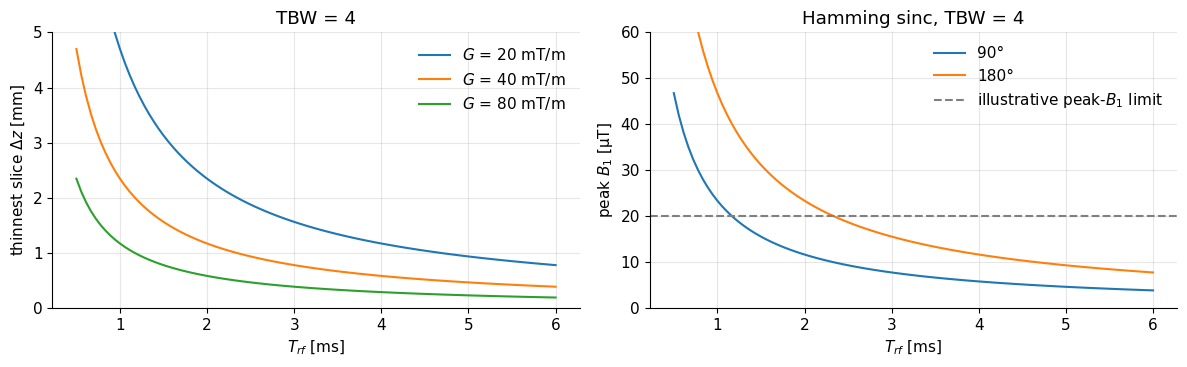

1 mm slice, TBW 4, T_rf 2 ms needs G = 47 mT/m


In [5]:
T = np.linspace(0.5e-3, 6e-3, 100)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for G in [20e-3, 40e-3, 80e-3]:
    ax[0].plot(T * 1e3, 4 / (mt.GAMMA_BAR * G * T) * 1e3, label=f"$G$ = {G*1e3:.0f} mT/m")
ax[0].set(xlabel=r"$T_{rf}$ [ms]", ylabel=r"thinnest slice $\Delta z$ [mm]", title="TBW = 4", ylim=(0, 5)); ax[0].legend()
peak = []
for Ti in T:
    _, b = sinc_pulse(4, Ti, Ti / 200, np.pi / 2); peak.append(np.abs(b).max())
ax[1].plot(T * 1e3, np.array(peak) * 1e6, label="90°")
ax[1].plot(T * 1e3, 2 * np.array(peak) * 1e6, label="180°")
ax[1].axhline(20, color="gray", ls="--", label="illustrative peak-$B_1$ limit")
ax[1].set(xlabel=r"$T_{rf}$ [ms]", ylabel="peak $B_1$ [µT]", title="Hamming sinc, TBW = 4", ylim=(0, 60)); ax[1].legend()
plt.tight_layout(); plt.show()
print(f"1 mm slice, TBW 4, T_rf 2 ms needs G = {4/(mt.GAMMA_BAR*2e-3*1e-3)*1e3:.0f} mT/m")

*Interpretation:* a 1 mm slice with a 2 ms, TBW-4 pulse needs ≈ 47 mT/m – near the hardware limit; with 40 mT/m you need ≈ 2.4 ms or longer. Short 180° pulses quickly exceed realistic peak-$B_1$ values, which is why refocusing pulses are often longer and/or have lower TBW than excitation pulses.

## Chemical-shift displacement of the slice

A spin's frequency is $f=\bar\gamma G_{z,SS}z+\Delta f$, where $\Delta f$ is any additional offset (chemical shift of fat, $B_0$ inhomogeneity). The pulse excites $|f-f_{off}|<BW_{rf}/2$, so spins with offset $\Delta f$ are excited in a slice centred at $z_{off}-\Delta f/(\bar\gamma G_{z,SS})$: their slice is **displaced** by

$$\Delta z_{cs}=-\frac{\Delta f_{cs}}{\bar\gamma\,G_{z,SS}}=-\Delta z\,\frac{\Delta f_{cs}}{BW_{rf}} .$$

*In words:* fat is excited in a slice shifted by the fraction $\Delta f_{cs}/BW_{rf}$ of the slice thickness; a wide-band pulse (or, equivalently, a strong gradient) keeps the shift small.

where $\Delta f_{cs}$ [Hz] is the fat–water frequency difference (≈ −447 Hz at 3 T, negative so fat moves toward $+z$ for a positive gradient), $\bar\gamma$ [Hz/T], $G_{z,SS}$ [T/m], $\Delta z$ [m], $BW_{rf}$ [Hz].

BW 1000 Hz: predicted shift 2.24 mm = 45 % of the slice
BW 4000 Hz: predicted shift 0.56 mm = 11 % of the slice


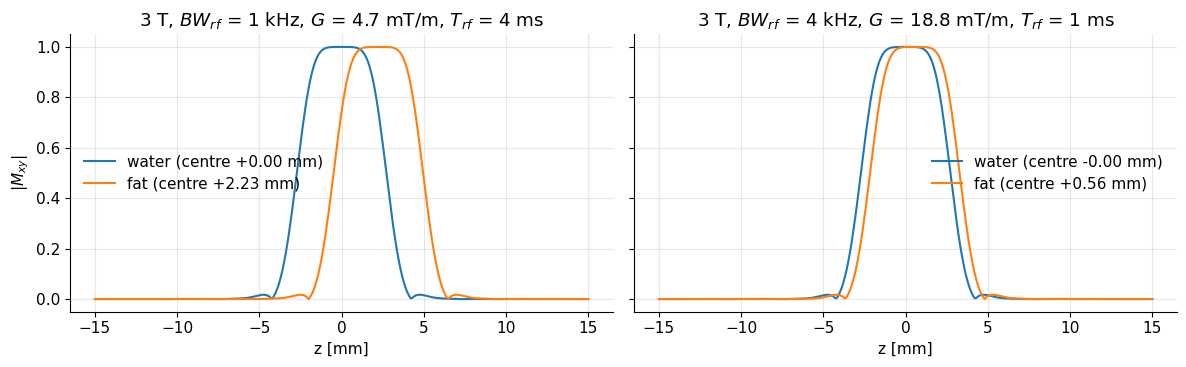

In [6]:
df_fat = mt.ppm_to_hz(mt.FAT_SHIFT_PPM, 3.0)          # [Hz] at 3 T
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for i, BWx in enumerate([1000.0, 4000.0]):
    Tx = TBW / BWx; Gx = BWx / (mt.GAMMA_BAR * dz)
    _, bx = sinc_pulse(TBW, Tx, dt)
    for dfv, lab in [(0.0, "water"), (df_fat, "fat")]:
        M = slice_select(bx, Gx, dt, z, df=dfv)
        p = np.abs(M[:, 0] + 1j * M[:, 1])
        ax[i].plot(z * 1e3, p, label=f"{lab} (centre {np.sum(p*z)/np.sum(p)*1e3:+.2f} mm)")
    ax[i].set(title=f"3 T, $BW_{{rf}}$ = {BWx/1e3:.0f} kHz, $G$ = {Gx*1e3:.1f} mT/m, $T_{{rf}}$ = {Tx*1e3:.0f} ms",
              xlabel="z [mm]"); ax[i].legend()
    print(f"BW {BWx:.0f} Hz: predicted shift {-df_fat/(mt.GAMMA_BAR*Gx)*1e3:.2f} mm = {-df_fat/BWx*100:.0f} % of the slice")
ax[0].set_ylabel(r"$|M_{xy}|$"); plt.tight_layout(); plt.show()

*Interpretation:* with a 1 kHz pulse at 3 T the fat slice is shifted by 2.2 mm – almost half of a 5 mm slice – so water and fat in the "same" image come from partly different tissue. A 4 kHz pulse reduces this to 0.56 mm. The same displacement happens for water itself wherever $B_0$ is inhomogeneous (by $\Delta f_r/(\bar\gamma G)$), bending the slice into a "potato chip" near air–tissue interfaces or metal ([I2 Artifacts](I2_Artifacts.ipynb)).

> **🧭 Intuition:** In a spin-echo sequence one can exploit this: if the 90° and 180° pulses have *different* bandwidths (or opposite gradient polarities), the fat slices of the two pulses do not overlap and fat produces no echo – the "slice-select gradient reversal" fat suppression trick. Spectral-spatial pulses ([J2](J2_Spectral-Spatial_RF_Pulses.ipynb)) avoid the problem by not exciting fat at all.

## Multi-slice imaging and slice cross-talk

In 2D multi-slice imaging, the slices excited in one $TR$ are placed side by side. Because real profiles are not perfect rectangles, neighbouring slices overlap at their edges ("cross-talk"): tissue at the boundary is partially saturated by the neighbour's pulse, reducing signal and changing contrast. Remedies: a **slice gap** (typically 10–30 % of $\Delta z$), interleaved slice ordering (odd slices first, then even), and sharper (higher TBW) pulses.

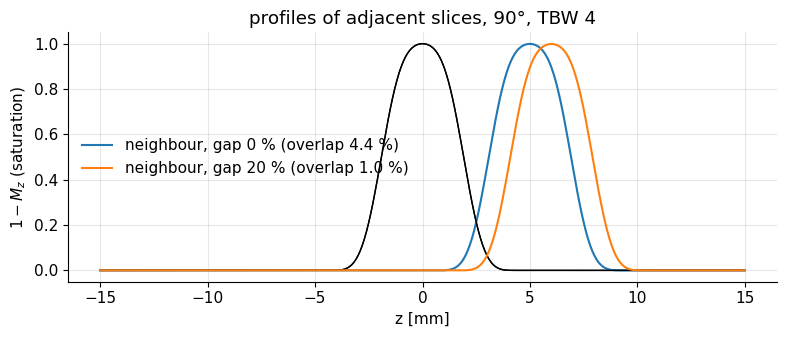

In [7]:
_, b30 = sinc_pulse(TBW, T_rf, dt, np.pi / 2)
fig, ax = plt.subplots(figsize=(8, 3.5))
for gap in [0.0, 0.2]:
    pitch = dz * (1 + gap)
    pA = 1 - slice_select(b30, G_ss, dt, z, f_off=0.0)[:, 2]                          # saturation by slice A
    pB = 1 - slice_select(b30, G_ss, dt, z, f_off=mt.GAMMA_BAR * G_ss * pitch)[:, 2]  # neighbour B
    overlap = np.sum(np.minimum(pA, pB)) / np.sum(pA)
    ax.plot(z * 1e3, pA, "k", lw=1); ax.plot(z * 1e3, pB, label=f"neighbour, gap {gap*100:.0f} % (overlap {overlap*100:.1f} %)")
ax.set(xlabel="z [mm]", ylabel=r"$1-M_z$ (saturation)", title="profiles of adjacent slices, 90°, TBW 4"); ax.legend()
plt.tight_layout(); plt.show()

*Interpretation:* with no gap, the transition bands of neighbouring slices overlap by ≈ 4 % of the slice profile; a 20 % gap reduces this to ≈ 1 %. Sharper SLR pulses ([E3](E3_RF_Pulse_Design.ipynb)) allow smaller gaps.

## Try it yourself (interactive)

In [8]:
try:
    from ipywidgets import interact, FloatSlider, IntSlider
    def explore(thickness_mm=5.0, T_ms=2.0, TBW_=4, flip_deg=90, rewind=0.5):
        T = T_ms * 1e-3; dts = T / 200
        _, b = sinc_pulse(TBW_, T, dts, np.deg2rad(flip_deg))
        G = TBW_ / T / (mt.GAMMA_BAR * thickness_mm * 1e-3)
        M = slice_select(b, G, dts, z, rewind_frac=rewind)
        plt.figure(figsize=(8, 3.5))
        plt.plot(z * 1e3, np.abs(M[:, 0] + 1j * M[:, 1]), label="|Mxy|"); plt.plot(z * 1e3, M[:, 1], label="My")
        plt.plot(z * 1e3, M[:, 2], label="Mz"); plt.legend(); plt.xlabel("z [mm]")
        plt.title(f"G = {G*1e3:.1f} mT/m, peak B1 = {np.abs(b).max()*1e6:.1f} µT"); plt.show()
    interact(explore, thickness_mm=FloatSlider(value=5, min=1, max=10, step=0.5), T_ms=FloatSlider(value=2, min=0.5, max=6, step=0.5),
             TBW_=IntSlider(value=4, min=2, max=12, step=2), flip_deg=IntSlider(value=90, min=10, max=180, step=10),
             rewind=FloatSlider(value=0.5, min=0, max=1, step=0.05))
except ImportError:
    print("ipywidgets not available - use the static cells above.")

interactive(children=(FloatSlider(value=5.0, description='thickness_mm', max=10.0, min=1.0, step=0.5), FloatSl…

## Key takeaways

* A gradient maps position to frequency, $f=\bar\gamma G_zz$ (426 Hz/mm at 10 mT/m); an RF pulse with bandwidth $BW_{rf}$ played during it excites a slice of thickness $\Delta z=BW_{rf}/(\bar\gamma G_{z,SS})$.
* The slice is moved by shifting the RF frequency: $f_{off}=\bar\gamma G_{z,SS}z_{off}$ (shift theorem: $b_1e^{-i2\pi f_{off}t}$).
* After a symmetric pulse the phase across the slice is linear, $\phi(z)=-\gamma zA_{SS}/2$; a rewinder of area $\approx-A_{SS}/2$ removes it. Without it only a few % of the signal remains. At 90° the exact optimum is slightly above ½.
* Thin slices need strong gradients and/or long pulses; short pulses cost peak $B_1$ and SAR.
* Fat (and any off-resonant spin) is excited in a displaced slice, $\Delta z_{cs}=-\Delta z\,\Delta f_{cs}/BW_{rf}$; wide-band pulses reduce the shift.
* Non-rectangular profiles cause cross-talk between adjacent slices; slice gaps and interleaving mitigate it.

## Check your understanding

1. You need a 3 mm slice with a pulse of bandwidth 1.5 kHz. What gradient amplitude do you need?

<details><summary>Answer</summary>

$G=BW_{rf}/(\bar\gamma\Delta z)=1500/(42.58\times10^6\cdot0.003)\approx11.7$ mT/m.

</details>

2. With that gradient, which RF frequency offset places the slice 45 mm from isocentre?

<details><summary>Answer</summary>

$f_{off}=\bar\gamma Gz_{off}=42.58\times10^6\cdot0.0117\cdot0.045\approx22.5$ kHz.

</details>

3. A colleague forgets the rewinder in a gradient-echo sequence. Why is the image almost black, and how would the problem change for a TBW-2 pulse?

<details><summary>Answer</summary>

The phase across the slice spans $\pi\cdot TBW$ radians; the coil sums over the slice and the phasors cancel. For TBW 2 the phase spans $2\pi$ (one full turn) – still nearly complete cancellation, but the residual depends on the exact profile shape.

</details>

4. At 3 T, how large must $BW_{rf}$ be for the fat slice to be displaced by less than 10 % of the slice thickness?

<details><summary>Answer</summary>

$|\Delta f_{cs}|/BW_{rf}<0.1\Rightarrow BW_{rf}>4.47$ kHz.

</details>

5. Why does a trapezoidal slice-select gradient need a slightly larger rewinder than $G_{z,SS}T_{rf}/2$?

<details><summary>Answer</summary>

Spins keep accumulating phase during the ramp-down after the RF ends; the rewinder must cancel the area from the pulse centre to the end of the ramp, i.e. $G_{z,SS}(T_{rf}/2+t_{ramp}/2)$.

</details>

---
*Adapted and extended from P. Larson, "Principles of MRI" (MIT License), chapter "Slice Selection".
Changes: added derivations of slice thickness/offset and of the −½ rewinder rule (small-tip phase), Bloch simulations of slice profiles, rewinder sweep, chemical-shift displacement, thin-slice trade-offs and cross-talk, with realistic numbers and engineering notes; clarified that the rewinder area is ≈ −½ (exactly ½ only in the small-tip limit for symmetric pulses).*